In [1]:

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/Dataset .csv")

In [ ]:
df.shape

(15, 11)

In [3]:
total_restaurants = len(df)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     object 
 1   Gender            15 non-null     object 
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     object 
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     object 
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     object 
 10  Churn             15 non-null     object 
dtypes: float64(2), int64(3), object(6)
memory usage: 1.4+ KB


In [4]:
table_booking = (
    df["Has Table booking"].value_counts()
)

online_delivery = (
    df["Has Online delivery"].value_counts()
)

table_yes = table_booking["Yes"]
delivery_yes = online_delivery["Yes"]

table_percentage = (table_yes / total_restaurants) * 100
delivery_percentage = (delivery_yes / total_restaurants) * 100

print("TOTAL RESTAURANTS:", total_restaurants)

TOTAL RESTAURANTS: 9551


In [5]:
print("\nTABLE BOOKING ANALYSIS")
print("Restaurants offering table booking:", table_yes)
print("Percentage:", round(table_percentage, 2), "%")


TABLE BOOKING ANALYSIS
Restaurants offering table booking: 1158
Percentage: 12.12 %


In [6]:
print("\nONLINE DELIVERY ANALYSIS")
print("Restaurants offering online delivery:", delivery_yes)
print("Percentage:", round(delivery_percentage, 2), "%")


ONLINE DELIVERY ANALYSIS
Restaurants offering online delivery: 2451
Percentage: 25.66 %


In [7]:
rated_df = df[df["Aggregate rating"] > 0]

average_ratings = rated_df.groupby(
    "Has Table booking"
)["Aggregate rating"].mean()

print("\nAVERAGE RESTAURANT RATINGS")
print(average_ratings.round(2))


AVERAGE RESTAURANT RATINGS
Has Table booking
No     3.41
Yes    3.59
Name: Aggregate rating, dtype: float64


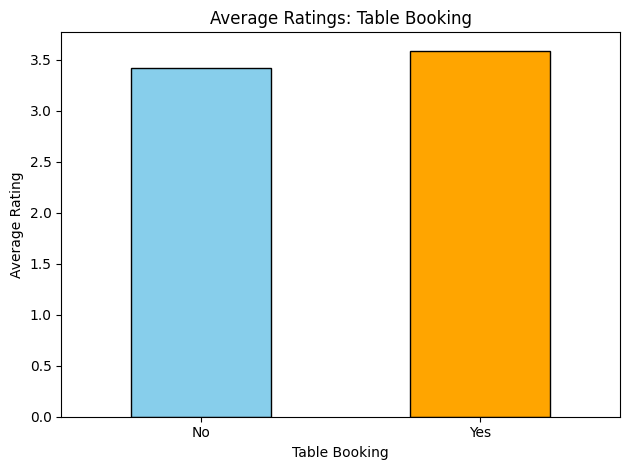

In [8]:
average_ratings.plot(
    kind="bar",
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.title("Average Ratings: Table Booking")
plt.xlabel("Table Booking")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
price_delivery = df.groupby("Price range")[
    "Has Online delivery"
].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("\nONLINE DELIVERY BY PRICE RANGE")
print(price_delivery.round(2))


ONLINE DELIVERY BY PRICE RANGE
Price range
1    15.77
2    41.31
3    29.19
4     9.04
Name: Has Online delivery, dtype: float64


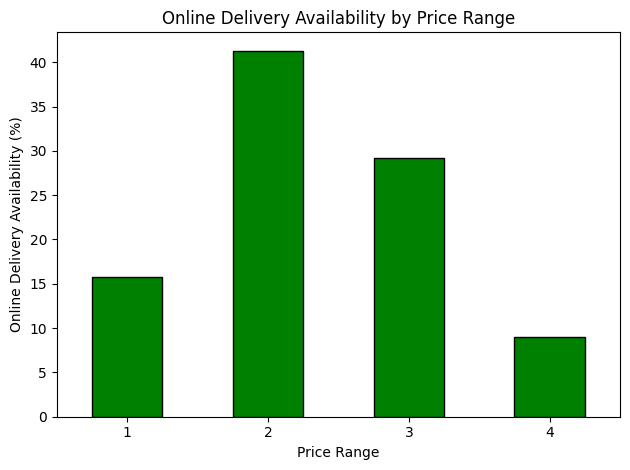

In [10]:
price_delivery.plot(
    kind="bar",
    color="green",
    edgecolor="black"
)

plt.title("Online Delivery Availability by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Online Delivery Availability (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:
print("\nFINAL SUMMARY")
print("Total Restaurants:", total_restaurants)
print("Table Booking:", round(table_percentage, 2), "%")
print("Online Delivery:", round(delivery_percentage, 2), "%")
print("Average Rating (No Table Booking):",
      round(average_ratings["No"], 2))
print("Average Rating (With Table Booking):",
      round(average_ratings["Yes"], 2))



FINAL SUMMARY
Total Restaurants: 9551
Table Booking: 12.12 %
Online Delivery: 25.66 %
Average Rating (No Table Booking): 3.41
Average Rating (With Table Booking): 3.59
